# Optimization for Machine Learning: Computer Lab 1

## 2. Preprocessing the data

Here, we load the data, standardize it, and set it in the appropriate shape for performing linear regression. You do not need to complete anything in this section; however it is important that you understand what the code is doing. See the pdf instructions for more details.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [33]:
# Loading data
data_matrix_train, COP_train, data_matrix_test, COP_test, names = np.load('data_center_data_matrix.npy', allow_pickle=True)

In [34]:
# centering and normalizing the matrix
matrix_mean = np.mean(data_matrix_train, axis=0)
M = data_matrix_train - matrix_mean

matrix_std = np.std(M, axis=0)
M = M / matrix_std

In [35]:
M.shape

(722, 892)

In [36]:
# Building the corresponding matrices A,b for linear regression
A = np.hstack([M, np.ones((M.shape[0],1)), -(M.T * COP_train[:,3]).T])
b = COP_train[:,3]

# Building the same matrices for the test set
M_test = (data_matrix_test - matrix_mean) / matrix_std
A_test = np.hstack([M_test, np.ones((M_test.shape[0],1)), -(M_test.T * COP_test[:,3]).T])
b_test = COP_test[:,3]

d = A.shape[1]

## 3. Ordinary least squares

We now wish to solve the problem
$$
\min_{w \in \mathbb{R}^d} \frac 12 \|Aw-b\|_2^2
$$
where $(Aw)_t = \tilde{x}(t)^T w_1 + w_0 - y(t) \times \tilde{x}(t)^T w_2$ for all $t$ and $b_t = y(t)$.

### Question 3.1:

Show that if $Aw = b$, then $y(t) = \dfrac{\tilde{x}(t)^T w_1 + w_0}{\tilde{x}(t)^T w_2 + 1}$.

*Solution:*

From the given equations, we can state that $(Aw)_t = b_t = y(t)$. Therefore, we may substitute this relation into the $(Aw)_t$ equation, obtaining:

$$
y(t) = \tilde{x}(t)^T w_1 + w_0 - y(t) \times \tilde{x}(t)^T w_2
$$

Then we reorganize the $y(t)$ terms such that they are on the left of the equality:

$$
y(t) + y(t) \times \tilde{x}(t)^T w_2 = \tilde{x}(t)^T w_1 + w_0
$$

$$
y(t) (1 + \tilde{x}(t)^T w_2) = \tilde{x}(t)^T w_1 + w_0
$$

And finally we can divide both sides by $1 + \tilde{x}(t)^T w_2$ and obtain the desired result:

$$
y(t) = \dfrac{\tilde{x}(t)^T w_1 + w_0}{\tilde{x}(t)^T w_2 + 1}
$$

In [7]:
## Question 3.2: solve with the numpy least squares solver

# COMPLETE HERE
w_least_squares = np.linalg.lstsq(A, b)[0]

In [8]:
## Question 3.3

# COMPLETE HERE
test_error = np.mean(np.square(A_test @ w_least_squares - b_test))
print("Test error for least squares solution : ", test_error)

Test error for least squares solution :  780.8984793523127


### Adding $\ell_2$ regularization

In order to improve the performance on the test set, we add $\ell_2$ regularization:

$$
\min_{w \in \mathbb{R}^d} \frac 12 \|Aw-b\|_2^2 + \frac \lambda 2 \|w\|_2^2
$$

### Question 3.4:

Calculate the gradient of $f_1$. Is the function convex? Is the gradient Lipschitz continuous?

*Solution:*

The gradient of $f_1$ is given by:

$$
\nabla f_1 = A^T(Aw-b) + \lambda w
$$

And the Hessian is:

$$
\nabla^2 f_1 = A^T A + \lambda I_d
$$

Since $A^TA$ is Positive Semi-Definite (PSD) and $\lambda$ is a positive constant, we can affirm that the hessian of $f_1$ is also PSD (and PD) and thus conclude that $f_1$ is convex (and strictly convex). Since the Hessian's biggest eigenvalue is finite, we can affirm that its spectral norm is bounded by L ($||\nabla^2f||_2 \le L$) and thus the gradient is Lipschitz continuous.

In [37]:
lambda_l2 = 1e4

In [38]:
 # Question 3.5
def f(w):
    return 1/2 * np.sum(np.square(A @ w - b)) + lambda_l2 /2 * np.sum(np.square(w))

def grad_f(w):
    return A.T @ (A @ w - b) + lambda_l2 * w

def gradient_descent(f, grad_f, w0, gamma, max_iter):
    w = w0.copy()

    f_values = []
    gradient_norms = []

    for t in range(max_iter):
        # COMPLETE HERE
        w = w - gamma * grad_f(w) # performs step and calculates new position

        f_values.append(f(w))
        gradient_norms.append(np.linalg.norm(grad_f(w)))

    return w, f_values, gradient_norms

To find the appropriate step size range, we need to estimate the Lipschitz constant of the gradient using the spectral norm of the Hessian.

In [39]:
# COMPLETE HERE
L = np.linalg.norm(A.T @ A + lambda_l2 * np.identity(d), ord = 2) # L bounds the spectral norm

In [40]:
# COMPLETE HERE
w0 = np.zeros(d)
step_size = 1/L # theoretical best step
max_iter = 3000 # arbitrary number of iterations

w_GD, f_values_GD, gradient_norms_GD = gradient_descent(f, grad_f, w0, step_size, max_iter)

We now compute the evolution of function values and gradient norm.

Iteration where gradient norm intercepts 1:  2339


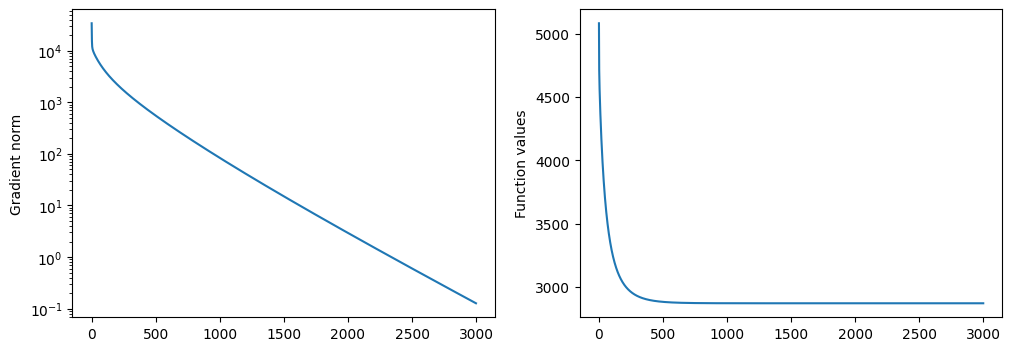

In [13]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].plot(gradient_norms_GD)
axes[0].semilogy()
axes[0].set_ylabel("Gradient norm")

axes[1].plot(f_values_GD)
axes[1].set_ylabel("Function values")

print('Iteration where gradient norm intercepts 1: ', np.argmin(np.abs(np.array(gradient_norms_GD) - 1)))

The gradient descent performs as expected and takes 2339 steps to reach the desired gradient norm of 1.

In [41]:
# Question 3.6

test_error_l2 = np.mean(np.pow(A_test @ w_GD - b_test, 2))
#test_error_l2 = np.mean(np.pow(A @ w_GD - b, 2))
print("Test error for l2 penalized solution : ", test_error_l2)

Test error for l2 penalized solution :  61.51838367542733


What do you observe ?

From the semi-log gradient graph we see that the algorithm converges at a linear rate, which is expected given the strictly convex objetive function employed in the algorithm. We can also see that by adding L2 regularization the test error decreases by one order of magnitude, indicating that the regularization leads to the training of a more general model.

### Line search

The step size given by theory can be too conservative in practice. We propose to implement a backtracking line search procedure to find a better one automatically.


In [42]:
# Question 3.7
# gradient descent with backtracking line search algorithm

def gradient_descent_line_search(f, grad_f, w0, gamma_0, max_iter):
    w = w0.copy()

    # initial step size
    gamma = gamma_0.copy()

    f_values = []
    gradient_norms = []

    # Backtracking line-search procedure
    for t in range(max_iter):
        gamma_plus = gamma

        grad = grad_f(w)
        while 1:
            w_new = w - gamma_plus * grad
            if f(w_new) <= f(w) + grad.T @ (w_new - w) + 1/(2 * gamma_plus) * np.sum(np.square(w_new - w)):
                w = w_new
                gamma = gamma_plus * 2 # accepts step if condition succeeds and doubles step size
                break
            else:
                gamma_plus = gamma_plus / 2 # halves step if condition fails

        f_values.append(f(w))
        gradient_norms.append(np.linalg.norm(grad))

    return w, f_values, gradient_norms

In [43]:
# COMPLETE HERE
w0 = np.zeros(d)
step_size = 1/L
max_iter = 1000

w_GD_LS, f_values_GD_LS, gradient_norms_GD_LS = gradient_descent_line_search(f, grad_f, w0, step_size, max_iter)

Text(0, 0.5, 'Function values with line search')

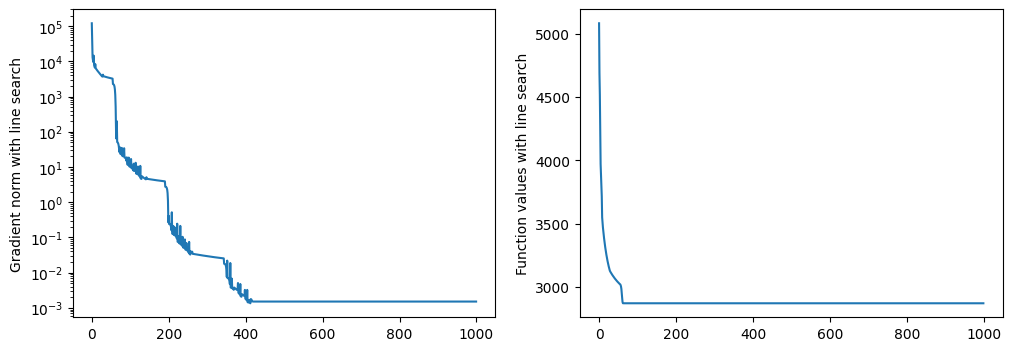

In [44]:
# let us plot the result
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].plot(gradient_norms_GD_LS)
axes[0].semilogy()
axes[0].set_ylabel("Gradient norm with line search")

axes[1].plot(f_values_GD_LS)
axes[1].set_ylabel("Function values with line search")

In [18]:
print('Iteration where gradient norm intercepts 1: ', np.argmin(np.abs(np.array(gradient_norms_GD_LS) - 1)))

Iteration where gradient norm intercepts 1:  197


The graph shows us that the line search algorithm converges a lot quicker than the previous algorithm, reaching the gradient norm of 1 in only 197 steps, approximately one order of magnitude quicker than the previous algorithm.

However its speed varies a lot and its steps not always lead to a smaller gradient, altough they always lead to a monotonic descent in the function.

### Accelerated gradient method
For a faster algorithm, we could implement accelerated gradient descent.

In [19]:
# Question 3.8 (optional)

def accelerated_gradient_descent(f, grad_f, w0, gamma, max_iter):
    w = w0.copy()

    f_values = []
    gradient_norms = []

    y_old = w0.copy()

    for t in range(max_iter):
        beta = (t + 1) / (t + 4)
        y = w - gamma * grad_f(w) # calculates gradient step
        w = y + beta * (y - y_old) # adds momentum step

        y_old = y
        f_values.append(f(w))
        gradient_norms.append(np.linalg.norm(grad_f(w)))

    return w, f_values, gradient_norms

In [20]:
# COMPLETE HERE
w0 = np.zeros(d)
step_size = 1/L
max_iter = 2000

w_AGD, f_values_AGD, gradient_norms_AGD = accelerated_gradient_descent(f, grad_f, w0, step_size, max_iter)

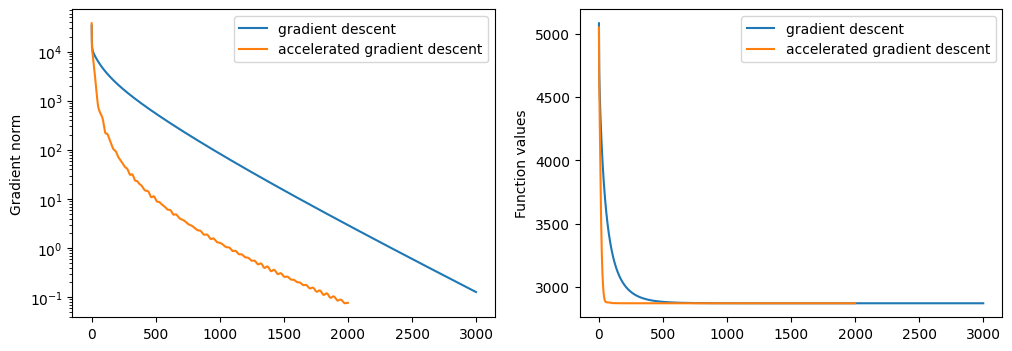

In [21]:
# let us plot the result
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].plot(gradient_norms_GD, label = "gradient descent")
axes[0].plot(gradient_norms_AGD, label = "accelerated gradient descent")
axes[0].semilogy()
axes[0].set_ylabel("Gradient norm")
axes[0].legend()

axes[1].plot(f_values_GD, label = "gradient descent")
axes[1].plot(f_values_AGD, label = "accelerated gradient descent")
axes[1].set_ylabel("Function values")
axes[1].legend()

What do you observe regarding the convergence speed ?

Accelerated gradient descent converges a lot quicker than the traditional method, but its not monotone, sometimes overshooting the target.

## 4. Adding $\ell_1$ regularization (Lasso)

We now solve

$$
\min_{w \in \mathbb{R}^d} \frac 12 \|Aw-b\|_2^2 + \lambda \|w\|_1
$$

### Question 4.1:

We first write the objetive function as $F_2 = f_2 + g_2$, where $f_2$ is differentiable and $g_2$ has a well defined proximal operator. Therefore, we must have:

$$
f_2(w) = \frac 12 \|Aw-b\|_2^2 \quad \text{and} \quad g_2(w) = \lambda \|w\|_1
$$

Then the proximal operator of $g_2$ is given by:

$$
\text{prox}_{g_2}(w) = S_\lambda(w)
$$

Where $S_\lambda(w)$ is the soft thresholding operator, described bellow:

$$
[S_\lambda(w)]^{(i)} = \begin{cases}
x^{(i)} + \lambda & \text{if} & x^{(i)} < -\lambda \\
0 & \text{if} & -\lambda \le x^{(i)} \le \lambda \\
x^{(i)} - \lambda & \text{if} & x^{(i)} > \lambda
\end{cases}
$$

At last, we calculate the gradient of $f_2$:

$$
\nabla f_2 (w) = A^T (A w - b)
$$

From these results, we can proceed with the implementation of the proximal gradient method.

In [22]:
lambda_l1 = 1e3

## Question 4.2
def prox_l1(x, mu = 1.): # proximal operator
    out = []
    for xi in x:
        if xi < -mu:
            out.append(xi + mu)
        elif xi > mu:
            out.append(xi - mu)
        else:
            out.append(0)

    return np.array(out)

def f(x):
    return 1/2 * np.sum(np.pow(A @ x - b, 2)) + lambda_l1 * np.sum(np.abs(x))

def grad_f(x):
    return A.T @ (A @ x - b) + lambda_l1 * np.sign(x)

# Uses step-size stopping criterion
def proximal_gradient_descent(f, grad_f, w0, gamma, max_iter, threshold):
    w = w0.copy()

    f_values = []
    gradient_norms = []
    w_old = np.inf

    for t in range(max_iter):
        # COMPLETE HERE
        w = prox_l1(w - gamma * grad_f(w), gamma * lambda_l1) # calculates step

        f_values.append(f(w))
        gradient_norms.append(np.linalg.norm(grad_f(w)))

        if np.linalg.norm(w - w_old) < threshold:
            break

        w_old = w

    return w, f_values, gradient_norms

In [23]:
# COMPLETE HERE
L = np.linalg.norm(A.T @ A, ord = 2)

w0 = np.zeros(d)
step_size = 1/L
max_iter = 1000
threshold = 1e-5

w_PGD, f_values_PGD, gradient_norms_PGD = proximal_gradient_descent(f, grad_f, w0, step_size, max_iter, threshold)

In [24]:
# Question 4.3

test_error_l1 = np.mean(np.pow(A_test @ w_PGD - b_test, 2))
print("Test error for l1 penalized solution : ", test_error_l1)

Test error for l1 penalized solution :  7.864445279634731


Compare with the previous test errors. What do you observe?

The $\ell_1$ (Lasso) regularization achieved the most significant performance gain thus far, yielding a test error approximately 50% lower than that of the $\ell_2$ (Ridge) solution. This improvement demonstrates the efficacy of the feature selection properties of the $\ell_1$ norm in this dataset. The Lasso model effectively sets coefficients of redundant or 'noisy' features to zero, reducing model complexity. This leads to superior generalization and a more robust performance on the test set.

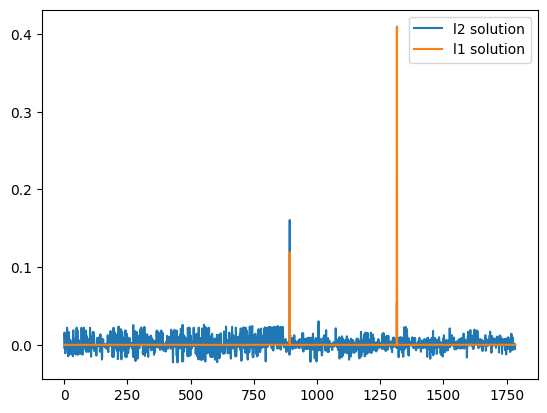

In [25]:
# Let us examine the solution
plt.plot(w_GD, label = "l2 solution")
plt.plot(w_PGD, label = "l1 solution")
plt.legend()

What do you observe regarding the difference in **structure** of the two solutions?

We can clearly see the $\ell_1$ regularization in action. While the $\ell_2$ penalized model attributes wheights to every feature of the model, the $\ell_1$ penalized model chooses only a small subset of features to which attribute wheights.

## [BONUS] Tuning the penalization parameter

How to find the best solution among all those that were comptued? How to choose the penalization parameter $\lambda$?

As detailed in the fifth section of the TP, we must generate models for a set of penalization parameters and evaluate their performance on the validation data through their MSE. Following this step, the chosen approach consists in simply choosing the penalization parameter that led to the model which better performed in the validation data.

Text(0, 0.5, 'MSE (Validation)')

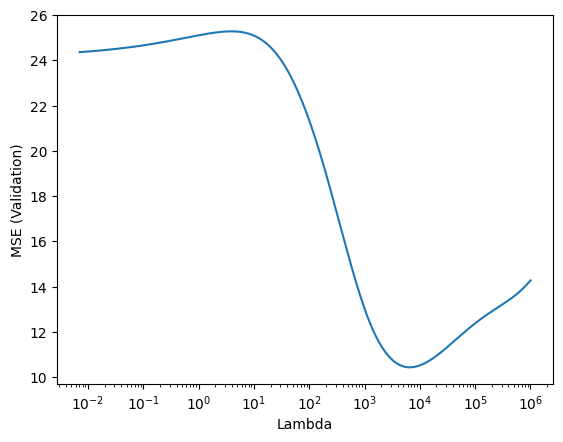

In [26]:
from sklearn.model_selection import train_test_split

# Split the original full training data (A, b) into a training set and a validation set
A_hyp_train, A_hyp_val, b_hyp_train, b_hyp_val = train_test_split(A, b, test_size=0.2, random_state=42)

lambda0 = 1000000
a = 0.91
K = 200
lambdas = lambda0 * np.pow(a, np.arange(0, K))

w0 = np.zeros(d)
max_iter = 300
val_errors_l2 = []
w_last = w0.copy()

L_inner = np.linalg.norm(A_hyp_train.T @ A_hyp_train, ord = 2)

# Modified f_tune and grad_f_tune to accept data matrices
def f_tune(w, lamb, A_matrix, b_vector):
    return 1/2 * np.sum(np.pow(A_matrix @ w - b_vector, 2)) + lamb /2 * np.sum(np.pow(w, 2))

def grad_f_tune(w, lamb, A_matrix, b_vector):
    return A_matrix.T @ (A_matrix @ w - b_vector) + lamb * w

for lam in lambdas:
    L = L_inner + lam
    step_size = 1/L

    # Create lambda functions that use the training data for optimization
    ft = lambda w_arg: f_tune(w_arg, lam, A_hyp_train, b_hyp_train)
    grad_ft = lambda w_arg: grad_f_tune(w_arg, lam, A_hyp_train, b_hyp_train)

    w_GD, f_values_GD, gradient_norms_GD = accelerated_gradient_descent(ft, grad_ft, w_last, step_size, max_iter)
    # Evaluate the model on the validation set
    val_errors_l2.append(np.mean(np.square(A_hyp_val @ w_GD - b_hyp_val)))
    w_last = w_GD.copy()

plt.plot(lambdas, val_errors_l2)
plt.semilogx()
plt.xlabel("Lambda")
plt.ylabel("MSE (Validation)")

In [27]:
print("Smallest validation error and corresponding lambda : ", min(val_errors_l2), lambdas[np.argmin(val_errors_l2)])

# Train new model with chosen lambda and calculate test error
ft = lambda w_arg: f_tune(w_arg, lambdas[np.argmin(val_errors_l2)], A, b)
grad_ft = lambda w_arg: grad_f_tune(w_arg, lambdas[np.argmin(val_errors_l2)], A, b)
w_GD, f_values_GD, gradient_norms_GD = accelerated_gradient_descent(ft, grad_ft, w0, step_size, 2000)
print("Test error : ", np.mean(np.square(A_test @ w_GD - b_test)))

Smallest validation error and corresponding lambda :  10.440779695308382 6748.2908607414265
Test error :  100.57379142403454


[]

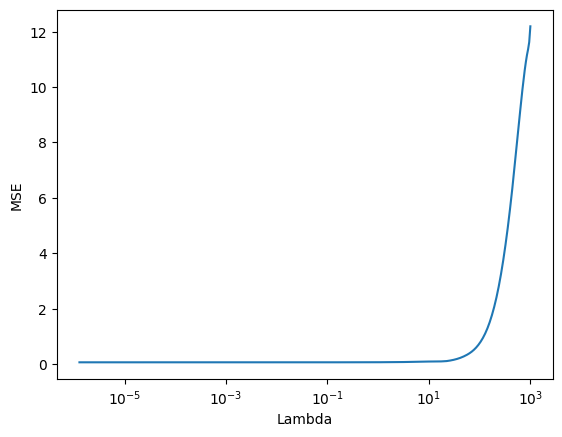

In [28]:
lambda0 = 1000
a = 0.95
K = 400
lambdas = lambda0 * np.pow(a, np.arange(0, K))
threshold = 5e-5

w0 = np.zeros(d)
L = np.linalg.norm(A_hyp_train.T @ A_hyp_train, ord = 2)
step_size = 1/L
max_iter = 400
val_errors_l1 = []
w_last = w0.copy()

def f_tune(w, lamb, A_matrix, b_matrix):
    return 1/2 * np.sum(np.pow(A_matrix @ w - b_matrix, 2)) + lamb * np.sum(np.abs(w))

# Uses step-size stopping criterion
def proximal_gradient_descent_tune(f, grad_f, w0, gamma, max_iter, threshold, lamb, A_matrix, b_matrix):
    w = w0.copy()

    f_values = []
    gradient_norms = []
    w_old = np.inf

    for t in range(max_iter):
        # COMPLETE HERE
        grad = A_matrix.T @ (A_matrix @ w - b_matrix) + lamb * np.sign(w)
        w = prox_l1(w - gamma * grad, gamma * lamb)

        f_values.append(f_tune(w, lamb, A_matrix, b_matrix))
        gradient_norms.append(np.linalg.norm(grad))

        if np.linalg.norm(w - w_old) < threshold:
            break

        w_old = w

    return w, f_values, gradient_norms

for lam in lambdas:
    w_PGD, f_values_PGD, gradient_norms_PGD = proximal_gradient_descent_tune(f_tune, grad_f, w_last, step_size, max_iter, threshold, lam, A_hyp_train, b_hyp_train)
    val_errors_l1.append(np.mean(np.pow(A_hyp_val @ w_PGD - b_hyp_val, 2)))
    w_last = w_PGD.copy()

plt.plot(lambdas, val_errors_l1)
plt.xlabel("Lambda")
plt.ylabel("MSE")
plt.semilogx()

In [29]:
print("Smallest validation error and corresponding lambda : ", min(val_errors_l1), lambdas[np.argmin(val_errors_l1)])

# Train new model with chosen lambda and calculate test error
w_PGD, f_values_PGD, gradient_norms_PGD = proximal_gradient_descent_tune(f_tune, grad_f, w_last, step_size, 1000, threshold, lam, A, b)
print("Test error : ", np.mean(np.square(A_test @ w_PGD - b_test)))

Smallest validation error and corresponding lambda :  0.06126272488884303 0.000254792808252614
Test error :  5.977269066406551
